# Mayavi smoke test

Checks that [Mayavi](https://docs.enthought.com/mayavi/mayavi/) is installed and can render.
Scenes are rendered **offscreen** and shown inline as PNGs, so this works in any Jupyter frontend.
The last cell opens a native interactive window.

In [1]:
import numpy as np
import vtk
import mayavi
from mayavi import mlab
from IPython.display import Image, display

print("Mayavi:", mayavi.__version__)
print("VTK:   ", vtk.vtkVersion.GetVTKVersion())

mlab.options.offscreen = True  # render without opening a window

def show(fig, name, size=(600, 450)):
    """Save the figure to a PNG, display it inline, and close it."""
    path = f"{name}.png"
    mlab.savefig(path, figure=fig, size=size)
    mlab.close(fig)
    display(Image(path))

Mayavi: 4.9.0
VTK:    9.7.1


## 1. Surface plot — `mlab.surf`

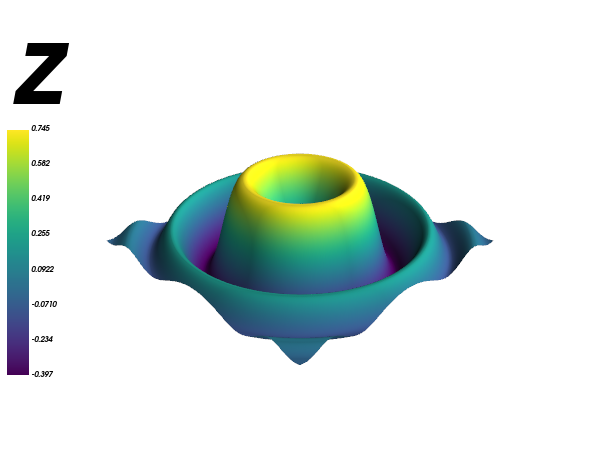

In [2]:
x, y = np.mgrid[-3:3:200j, -3:3:200j]
z = np.sin(x**2 + y**2) * np.exp(-0.2 * (x**2 + y**2))

fig = mlab.figure(bgcolor=(1, 1, 1), fgcolor=(0, 0, 0))
mlab.surf(x, y, z, colormap="viridis", warp_scale=2)
mlab.colorbar(orientation="vertical", title="z")
mlab.view(azimuth=45, elevation=60, distance="auto")
show(fig, "surface")

## 2. Parametric mesh — `mlab.mesh` (spherical harmonic)

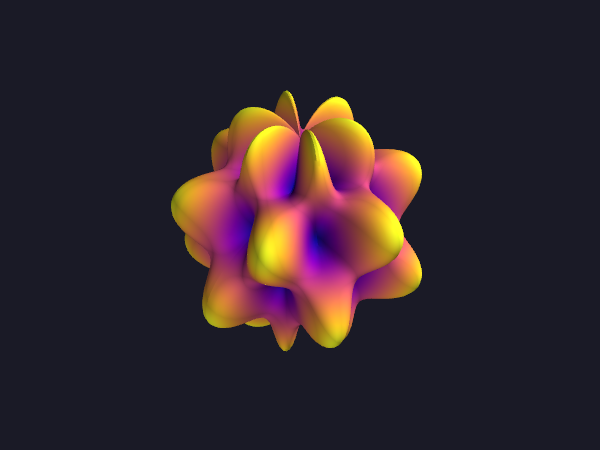

In [3]:
phi, theta = np.mgrid[0:np.pi:150j, 0:2 * np.pi:150j]
r = 1 + 0.35 * np.sin(4 * phi) * np.cos(6 * theta)
xs = r * np.sin(phi) * np.cos(theta)
ys = r * np.sin(phi) * np.sin(theta)
zs = r * np.cos(phi)

fig = mlab.figure(bgcolor=(0.1, 0.1, 0.15))
mlab.mesh(xs, ys, zs, scalars=r, colormap="plasma")
show(fig, "mesh")

## 3. 3D scatter + line — `mlab.points3d` / `mlab.plot3d`

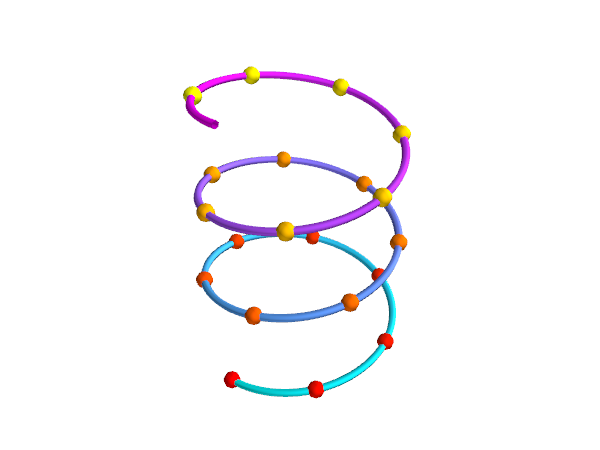

In [4]:
t = np.linspace(0, 6 * np.pi, 400)
hx, hy, hz = np.cos(t), np.sin(t), t / (2 * np.pi)

fig = mlab.figure(bgcolor=(1, 1, 1))
mlab.plot3d(hx, hy, hz, t, tube_radius=0.04, colormap="cool")
mlab.points3d(hx[::20], hy[::20], hz[::20], t[::20], scale_mode="none",
              scale_factor=0.18, colormap="autumn")
show(fig, "helix")

## 4. Volume isosurfaces — `mlab.contour3d`

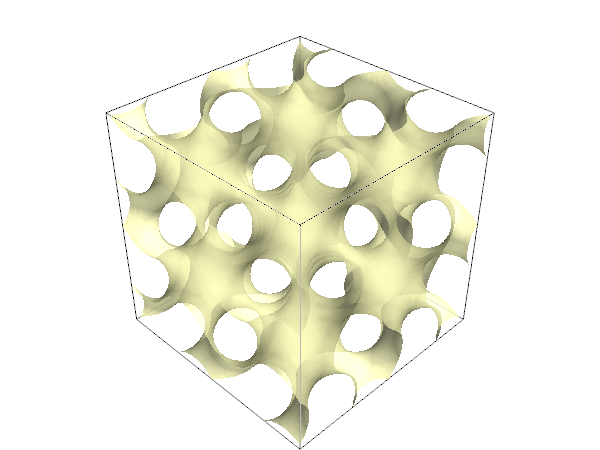

In [5]:
gx, gy, gz = np.ogrid[-2:2:64j, -2:2:64j, -2:2:64j]
# Gyroid-like implicit surface
field = np.sin(3 * gx) * np.cos(3 * gy) + np.sin(3 * gy) * np.cos(3 * gz) + np.sin(3 * gz) * np.cos(3 * gx)

fig = mlab.figure(bgcolor=(1, 1, 1))
mlab.contour3d(field, contours=[0.0], colormap="Spectral", opacity=0.9)
mlab.outline(color=(0, 0, 0))
show(fig, "isosurface")

## 5. Interactive window

Opens a native Qt window you can rotate/zoom. Close the window to continue.
Needs a display, so skip this cell on a headless machine.

In [6]:
%gui qt
mlab.options.offscreen = False
mlab.test_plot3d()
mlab.show()